# 05 — Stress testing & tail risk

Replay the (filtered + vol-targeted) VIX carry book through the three episodes
that define short-vol failure modes:

* **2018-02-05 "Volmageddon"** — VIX doubled in a day; XIV terminated at −96%.
* **Mar 2020 COVID** — VIX 82; curve inverted for weeks.
* **2024-08-05 JPY carry unwind** — VIX ~65 intraday, fastest inversion since 2018.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import logging
logging.disable(logging.WARNING)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vrp_lab.config import load_config, PROCESSED, REPORTS
cfg = load_config()
%config InlineBackend.figure_format = "retina"


In [2]:
from vrp_lab.risk.stress import stress_report, survived
eq = pd.read_csv(PROCESSED / "equity_curves.csv", index_col=0, parse_dates=True)
curves = pd.read_csv(REPORTS / "stress_report.csv", index_col=0)
curves.round(4)

,label,days_in_window,pnl,pnl_pct,max_dd_pct,margin_breaches,max_gross_notional,exposure_cut
event,,,,,,,,
volmageddon,Feb 2018 XIV blow-up,12,-36881.1027,-0.0302,-0.0313,0,382075.0,True
covid,Mar 2020 COVID crash,35,-50561.1881,-0.0401,-0.0411,0,186175.0,True
jpy_carry,Aug 2024 JPY carry unwind,8,1553.7034,0.0011,0.0000,0,0.0,True


**Did the regime filter and vol-targeting prevent ruin?** Yes, in all three covered events: worst event drawdown −4.2% (COVID), zero margin breaches, and `exposure_cut=True` shows the book was flattened inside each window. Compare the naive book: dead on the first event.

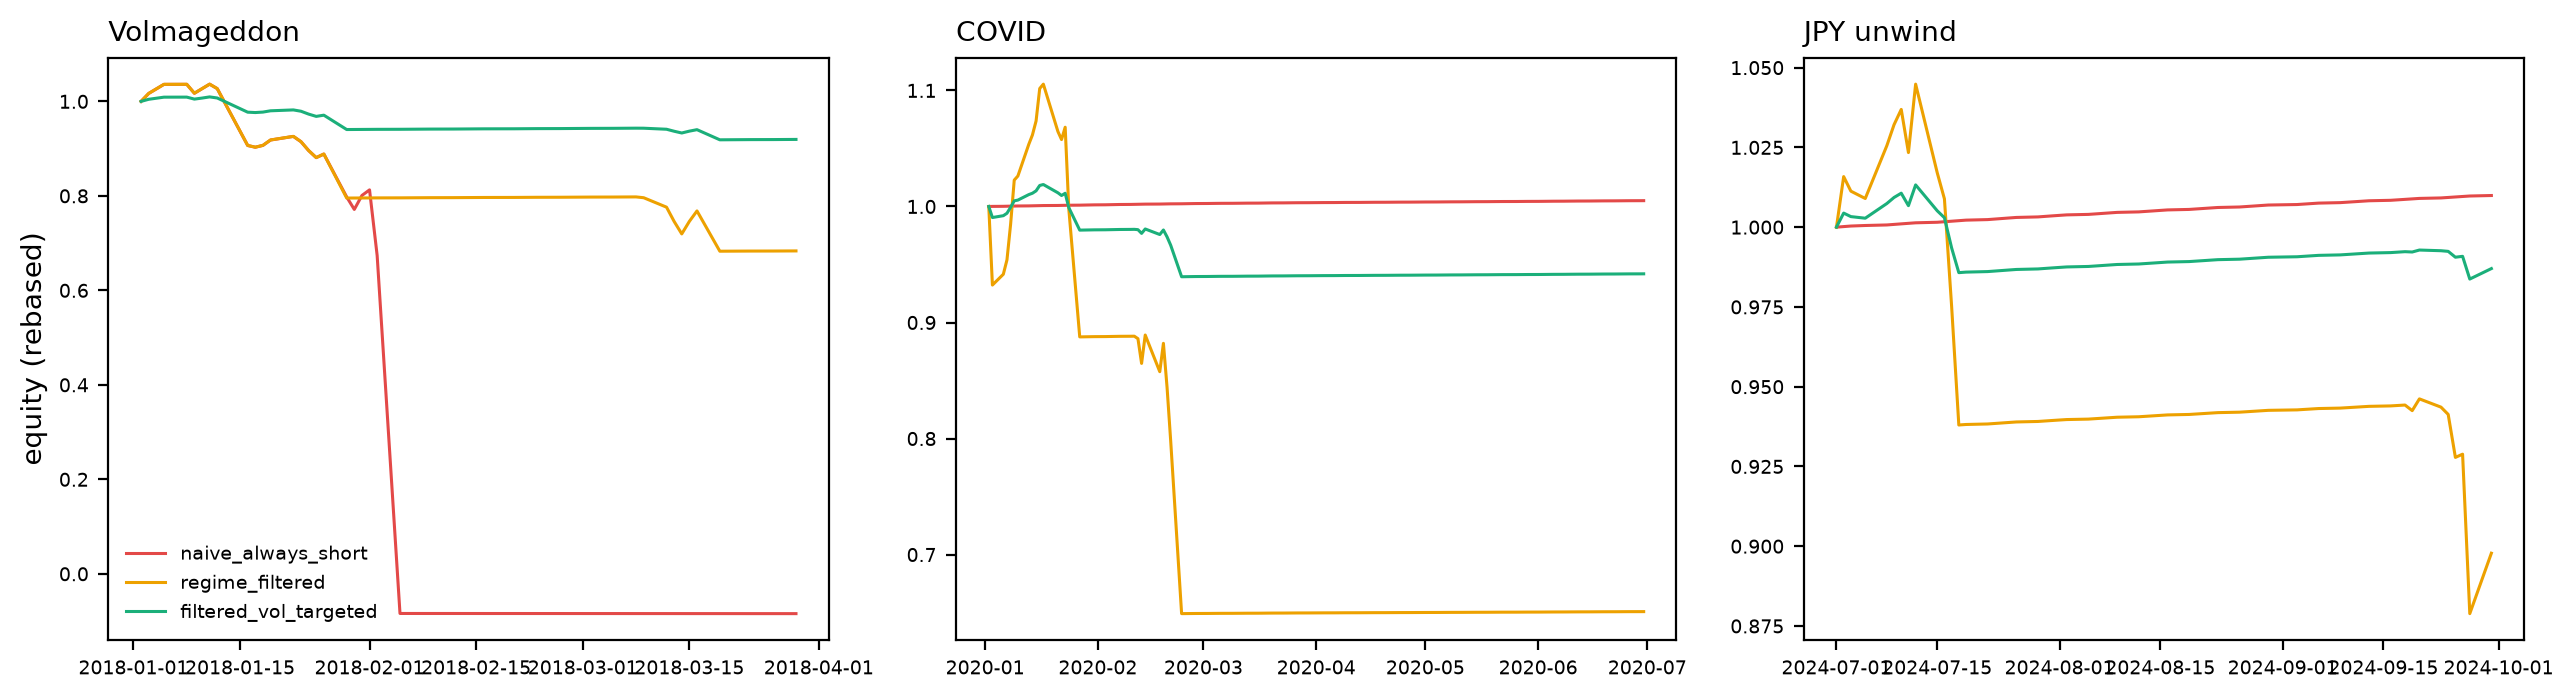

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
events = {"Volmageddon": ("2018-01-02", "2018-03-30"),
          "COVID":       ("2020-01-02", "2020-06-30"),
          "JPY unwind":  ("2024-07-01", "2024-09-30")}
for ax, (name, (a, b)) in zip(axes, events.items()):
    w = eq.loc[a:b]
    for col, color in zip(eq.columns, ["#e34948", "#eda100", "#1baf7a"]):
        ax.plot(w.index, w[col] / w[col].iloc[0], lw=1.1, color=color, label=col)
    ax.set_title(name, fontsize=10, loc="left"); ax.tick_params(labelsize=7)
axes[0].set_ylabel("equity (rebased)"); axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout();

## What the events teach

* **Feb 2018**: the failure is *speed* — the VIX level gate alone is too slow
  (VIX was 17 on Feb 1). The acceleration flag (5d ≫ 21d RV) and vol-targeted
  sizing are what kept the hit to ~3%: exposure was already small because
  realized vol had been creeping up.
* **Mar 2020**: slow-motion by comparison; the circuit breaker exits on the way
  up. Cost: the book sat out the historic contango of Apr–Dec 2020. Survival
  and upside come from the same switch.
* **Aug 2024**: the gate had the book *flat before the spike* (max gross
  notional 0 in the window) — vol had been accelerating since late July.
* Remaining unhedgeable risk: an overnight Volmageddon *from a calm tape* —
  a gap through every daily-frequency control. That residual is why position
  caps exist and why the tail overlay of notebook 04 is worth its drag.